In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q transformers datasets torchaudio librosa scikit-learn seaborn

In [ ]:
import os
import torch
import librosa
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from transformers import (
    Wav2Vec2Processor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
IESC_PATH = "/content/drive/MyDrive/Datasets/IESC_Hindi"
RAVDESS_PATH = "/content/drive/MyDrive/Datasets/RAVDESS/AudioFiles"

SAVE_PATH = "/content/drive/MyDrive/Models/Multilingual_SER"

In [ ]:
data = []

for speaker in os.listdir(IESC_PATH):

    speaker_path = os.path.join(IESC_PATH, speaker)

    if not os.path.isdir(speaker_path):
        continue

    for session in os.listdir(speaker_path):

        session_path = os.path.join(speaker_path, session)

        if not os.path.isdir(session_path):
            continue

        for emotion in os.listdir(session_path):

            emotion_path = os.path.join(session_path, emotion)

            if not os.path.isdir(emotion_path):
                continue

            for file in os.listdir(emotion_path):

                if file.endswith(".wav"):

                    data.append({
                        "dataset":"IESC",
                        "emotion":emotion.lower(),
                        "path":os.path.join(emotion_path,file)
                    })

iesc_df = pd.DataFrame(data)

print("IESC samples:", len(iesc_df))

IESC samples: 3200


In [ ]:
ravdess_data = []

ravdess_map = {
"01":"neutral",
"03":"happy",
"04":"sad",
"05":"anger"
}

for actor in os.listdir(RAVDESS_PATH):

    actor_path = os.path.join(RAVDESS_PATH, actor)

    if not os.path.isdir(actor_path):
        continue

    for file in os.listdir(actor_path):

        parts = file.split("-")
        emotion = parts[2]

        if emotion in ravdess_map:

            ravdess_data.append({
                "dataset":"RAVDESS",
                "emotion":ravdess_map[emotion],
                "path":os.path.join(actor_path,file)
            })

ravdess_df = pd.DataFrame(ravdess_data)

print("RAVDESS samples:", len(ravdess_df))

RAVDESS samples: 672


In [ ]:
selected_emotions = ["anger","happy","sad","neutral"]

iesc_df = iesc_df[iesc_df["emotion"].isin(selected_emotions)]
ravdess_df = ravdess_df[ravdess_df["emotion"].isin(selected_emotions)]

print("Filtered IESC:", len(iesc_df))
print("Filtered RAVDESS:", len(ravdess_df))

Filtered IESC: 1600
Filtered RAVDESS: 672


In [ ]:
emotions = sorted(selected_emotions)

label2id = {label:i for i,label in enumerate(emotions)}
id2label = {i:label for label,i in label2id.items()}

iesc_df["label"] = iesc_df["emotion"].map(label2id)
ravdess_df["label"] = ravdess_df["emotion"].map(label2id)

In [ ]:
train_df = pd.concat([iesc_df, ravdess_df])

train_df, val_df = train_test_split(
    train_df,
    test_size=0.1,
    stratify=train_df["label"],
    random_state=42
)

In [ ]:
test_df = ravdess_df.copy()

In [ ]:
train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset = Dataset.from_pandas(val_df.reset_index(drop=True))
test_dataset = Dataset.from_pandas(test_df.reset_index(drop=True))

In [ ]:
MODEL_NAME = "facebook/wav2vec2-base"

processor = Wav2Vec2Processor.from_pretrained(MODEL_NAME)

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(emotions),
    label2id=label2id,
    id2label=id2label
).to(device)

model.freeze_feature_encoder()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_q.weight             | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
projector.bias               | MISSING    | 
classifier.bias              | MISSING    | 
projector.weight             | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
TARGET_SAMPLING_RATE = 16000

def preprocess(batch):

    speech, sr = librosa.load(batch["path"], sr=TARGET_SAMPLING_RATE)

    batch["input_values"] = processor(
        speech,
        sampling_rate=TARGET_SAMPLING_RATE
    ).input_values[0]

    batch["labels"] = batch["label"]

    return batch

In [ ]:
train_dataset = train_dataset.map(preprocess, remove_columns=train_dataset.column_names)
val_dataset = val_dataset.map(preprocess, remove_columns=val_dataset.column_names)
test_dataset = test_dataset.map(preprocess, remove_columns=test_dataset.column_names)

train_dataset.set_format("torch")
val_dataset.set_format("torch")
test_dataset.set_format("torch")

Map:   0%|          | 0/2044 [00:00<?, ? examples/s]

Map:   0%|          | 0/228 [00:00<?, ? examples/s]

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=processor,
    padding=True,
    return_tensors="pt"
)

In [ ]:
training_args = TrainingArguments(

    output_dir=SAVE_PATH,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    num_train_epochs=15,

    fp16=True,

    load_best_model_at_end=True,
    metric_for_best_model="accuracy",

    save_total_limit=2,

    logging_steps=50,
    report_to="none"
)

In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    preds = np.argmax(logits, axis=1)

    acc = accuracy_score(labels, preds)

    return {"accuracy": acc}

In [ ]:
trainer = Trainer(

    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    data_collator=data_collator,
    compute_metrics=compute_metrics,

    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.874342,0.817619,0.662281
2,0.532396,0.559777,0.802632
3,0.334090,0.584291,0.815789
4,0.340136,0.530452,0.859649
5,0.184411,0.331364,0.921053
6,0.172400,0.577311,0.881579
7,0.131804,0.368371,0.929825


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3840, training_loss=0.22361514968797563, metrics={'train_runtime': 914.7146, 'train_samples_per_second': 33.519, 'train_steps_per_second': 4.198, 'total_flos': 1.1560578995686792e+18, 'train_loss': 0.22361514968797563, 'epoch': 15.0})

In [ ]:
predictions = trainer.predict(test_dataset)

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

print("\nTest Accuracy:", round(accuracy_score(y_true, y_pred)*100,2),"%")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    target_names=emotions,
    digits=4
))


Test Accuracy: 99.55 %

Classification Report:

              precision    recall  f1-score   support

       anger     1.0000    1.0000    1.0000       192
       happy     0.9896    0.9948    0.9922       192
     neutral     1.0000    1.0000    1.0000        96
         sad     0.9948    0.9896    0.9922       192

    accuracy                         0.9955       672
   macro avg     0.9961    0.9961    0.9961       672
weighted avg     0.9955    0.9955    0.9955       672



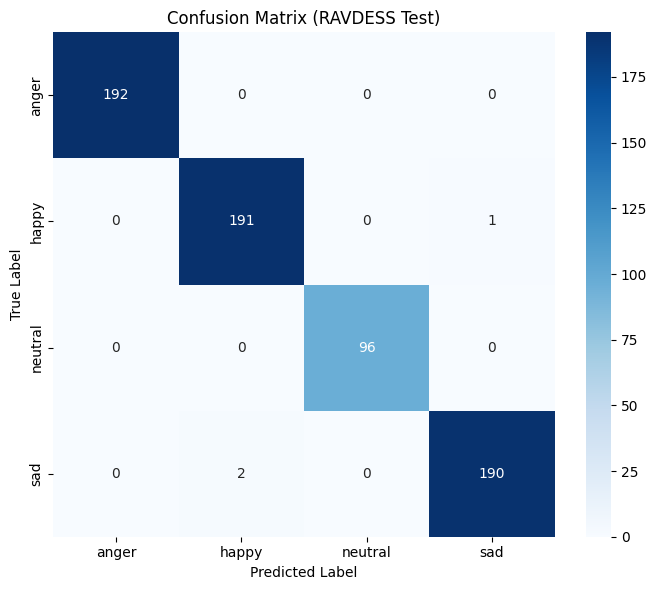

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotions,
    yticklabels=emotions
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title("Confusion Matrix (RAVDESS Test)")

plt.tight_layout()
plt.show()

In [ ]:
pkl_path = SAVE_PATH + "/wav2vec2_ser_model.pkl"

with open(pkl_path, "wb") as f:

    pickle.dump({
        "model_state_dict": model.state_dict(),
        "label2id": label2id,
        "id2label": id2label
    }, f)

print("Model saved as PKL:", pkl_path)

Model saved as PKL: /content/drive/MyDrive/Models/Multilingual_SER/wav2vec2_ser_model.pkl


In [ ]:
import os
import pickle

# New folder path
PKL_SAVE_PATH = "/content/drive/MyDrive/PickleModels"

# Create folder if it doesn't exist
os.makedirs(PKL_SAVE_PATH, exist_ok=True)

# Full pickle file path
pkl_path = os.path.join(PKL_SAVE_PATH, "wav2vec2_ser_model.pkl")

# Save model
with open(pkl_path, "wb") as f:
    pickle.dump({
        "model_state_dict": model.state_dict(),
        "label2id": label2id,
        "id2label": id2label
    }, f)

print("Model saved as PKL at:", pkl_path)

Model saved as PKL at: /content/drive/MyDrive/PickleModels/wav2vec2_ser_model.pkl
